In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

# Membaca dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Melihat lima data pertama
display(df.head())

# Melihat informasi dataset
df.info()

# Mengecek missing values
print("\nMissing values:")
print(df.isnull().sum())

# Melihat nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Missing values:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Nama kolom:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


##### 1. Creating a scatter plot based 'Avg_Credit_Limit' vs 'Total_Credit_Cards'

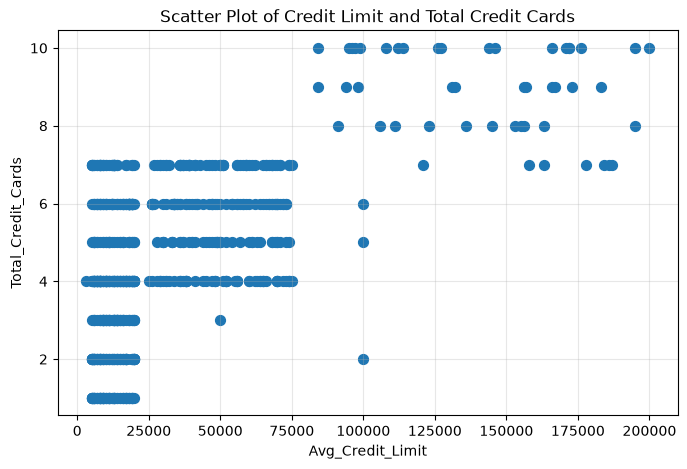

In [8]:
# Menentukan nama kolom jumlah kartu kredit
credit_card_col = next(
    (col for col in df.columns
     if col.lower() in ['total_credit_cards', 'total_credit_card']),
    None
)

if 'Avg_Credit_Limit' not in df.columns or credit_card_col is None:
    raise ValueError(
        "Kolom Avg_Credit_Limit atau kolom jumlah kartu kredit tidak ditemukan. "
        "Periksa nama kolom pada dataset."
    )

# Mengambil dua variabel
plot_df = df[['Avg_Credit_Limit', credit_card_col]].dropna()

# Membuat scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(
    plot_df['Avg_Credit_Limit'],
    plot_df[credit_card_col],
    s=50
)

plt.xlabel('Avg_Credit_Limit')
plt.ylabel(credit_card_col)
plt.title('Scatter Plot of Credit Limit and Total Credit Cards')
plt.grid(True, alpha=0.3)
plt.show()


Apakah distribusi data dapat dianggap linear?

Tidak.terdapat tren positif (korelasi Pearson sekitar 0,61): semakin besar limit kredit, cenderung semakin banyak kartu kredit. Namun titik-titik tidak membentuk pola garis lurus, melainkan berkelompok seperti blok/tangga:

- limit rendah (di bawah sekitar 20.000) dengan 1-4 kartu,
- limit menengah (sekitar 20.000-75.000) dengan 4-7 kartu,
- limit tinggi (di atas sekitar 85.000) dengan 7-10 kartu.


Karena Total_Credit_Cards bernilai bilangan bulat dan data terkumpul dalam kelompok-kelompok, sebaran ini lebih cocok dianggap sebagai kelompok (cluster) daripada hubungan linear. Itulah alasan clustering cocok dipakai di sini.

##### 2. Create K-Means model and determining the number of clusters using the Elbow Method

In [9]:
# Kolom yang hanya berfungsi sebagai identitas
id_keywords = ['id', 'sl_no', 'customer_key', 'customer_id']

# Memilih kolom numerik
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Menghapus kolom identitas
feature_cols = [
    col for col in numeric_cols
    if not any(key in col.lower() for key in id_keywords)
]

print("Fitur yang digunakan:")
print(feature_cols)

# Membuat dataset fitur
X = df[feature_cols].copy()

# Mengatasi missing values menggunakan median
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nUkuran data:", X_scaled.shape)

Fitur yang digunakan:
['Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Ukuran data: (660, 6)


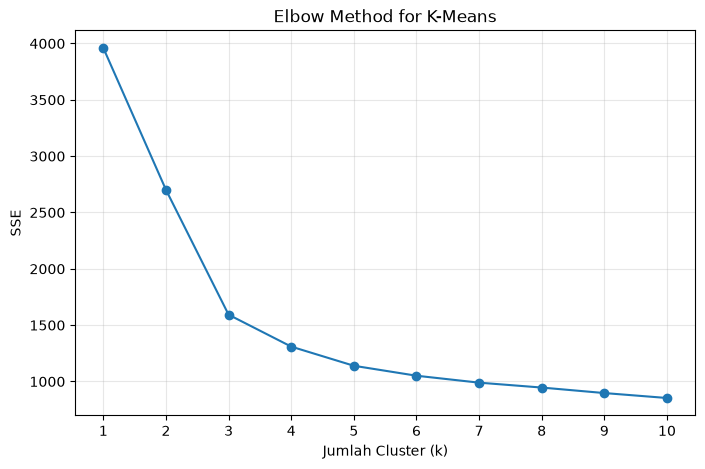

k = 1, SSE = 3960.0000
k = 2, SSE = 2700.9848
k = 3, SSE = 1592.8133
k = 4, SSE = 1309.5102
k = 5, SSE = 1139.5077
k = 6, SSE = 1051.1468
k = 7, SSE = 989.5915
k = 8, SSE = 946.1610
k = 9, SSE = 897.3078
k = 10, SSE = 853.4727


In [10]:
sse = []
K = range(1, 11)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    sse.append(model.inertia_)

# Membuat grafik Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K, sse, marker='o')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE')
plt.title('Elbow Method for K-Means')
plt.xticks(list(K))
plt.grid(True, alpha=0.3)
plt.show()

# Menampilkan nilai SSE
for k, value in zip(K, sse):
    print(f'k = {k}, SSE = {value:.4f}')

In [11]:
# Ganti angka 3 jika hasil Elbow Method menunjukkan nilai lain
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("Jumlah cluster:", best_k)
print("SSE K-Means:", kmeans.inertia_)
print("Jumlah data pada setiap cluster:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

Jumlah cluster: 3
SSE K-Means: 1592.8133253795986
Jumlah data pada setiap cluster:
0    386
1     50
2    224
Name: count, dtype: int64


SSE turun sangat tajam dari k=1 (sekitar 1320) ke k=2 (sekitar 698) dan ke k=3 (sekitar 335). Setelah k=3, penurunannya jauh lebih landai (k=4 sekitar 235, k=5 sekitar 164, dan seterusnya). Titik tempat penurunan tajam berhenti dan berganti menjadi landai itulah "siku" (elbow), yaitu k = 3.

SSE pasti terus turun saat k bertambah karena tiap cluster makin kecil dan makin rapat, jadi SSE kecil saja tidak berarti k itu ideal. Yang dicari adalah k terakhir yang masih memberi penurunan signifikan. Pilihan k=3 juga sesuai dengan scatter plot Soal 1 yang memperlihatkan tiga kelompok (limit rendah, menengah, tinggi).

##### 3. Display K-Means clustering results using a scatter plot

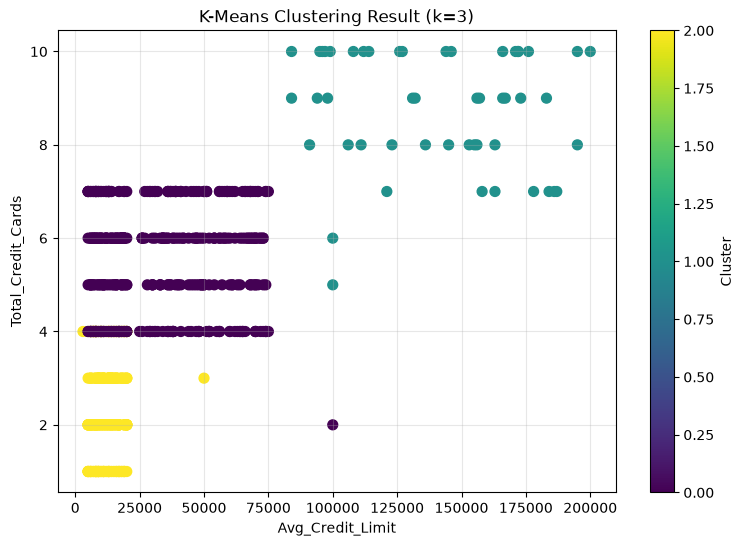

In [12]:
# Mengambil dua fitur untuk visualisasi
x_col = 'Avg_Credit_Limit'
y_col = credit_card_col

# Membuat salinan data untuk visualisasi
viz_df = df[[x_col, y_col]].copy()
viz_df['Cluster'] = kmeans_labels

# Menghapus baris yang tidak memiliki nilai pada dua variabel visualisasi
viz_df = viz_df.dropna()

# Membuat scatter plot berdasarkan hasil clustering
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    viz_df[x_col],
    viz_df[y_col],
    c=viz_df['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title(f'K-Means Clustering Result (k={best_k})')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()


Hasil clustering K-Means divisualisasikan menggunakan scatter plot berdasarkan variabel Avg_Credit_Limit dan jumlah kartu kredit. Setiap warna merepresentasikan cluster yang berbeda. Visualisasi digunakan untuk mengamati persebaran pelanggan dan perbedaan karakteristik antarkelompok. Pemisahan cluster pada grafik merupakan gambaran dua dimensi dari hasil model yang dibangun menggunakan seluruh fitur terpilih.

##### 4. 

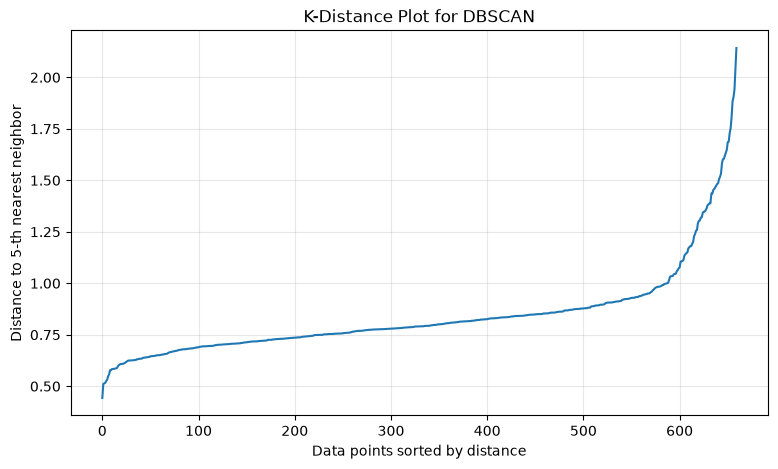

In [13]:
# Menentukan min_samples awal
min_samples = 5

# Menghitung jarak ke tetangga terdekat ke-min_samples
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Mengambil jarak ke tetangga terakhir dan mengurutkannya
k_distances = np.sort(distances[:, -1])

# Membuat k-distance plot
plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel('Data points sorted by distance')
plt.ylabel(f'Distance to {min_samples}-th nearest neighbor')
plt.title('K-Distance Plot for DBSCAN')
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
# Nilai awal; sesuaikan berdasarkan k-distance plot
eps_value = 0.5

dbscan = DBSCAN(
    eps=eps_value,
    min_samples=min_samples
)

dbscan_labels = dbscan.fit_predict(X_scaled)

# Label -1 berarti noise
n_clusters_dbscan = len(set(dbscan_labels)) - (
    1 if -1 in dbscan_labels else 0
)

n_noise = np.sum(dbscan_labels == -1)

print("Eps:", eps_value)
print("Min samples:", min_samples)
print("Jumlah cluster DBSCAN:", n_clusters_dbscan)
print("Jumlah data noise:", n_noise)

print("\nJumlah data per label:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

Eps: 0.5
Min samples: 5
Jumlah cluster DBSCAN: 1
Jumlah data noise: 655

Jumlah data per label:
-1    655
 0      5
Name: count, dtype: int64


Model DBSCAN dibangun menggunakan seluruh fitur numerik yang relevan setelah proses penanganan missing values dan standardisasi. Parameter eps ditentukan dengan bantuan k-distance plot, sedangkan min_samples ditetapkan sebagai jumlah minimum titik untuk membentuk area padat. DBSCAN kemudian mengelompokkan pelanggan berdasarkan kepadatan data dan mengidentifikasi pelanggan yang tidak memenuhi kriteria kepadatan sebagai noise.

##### 5. Menentukan parameter dengan Elbow Method (k-distance plot)

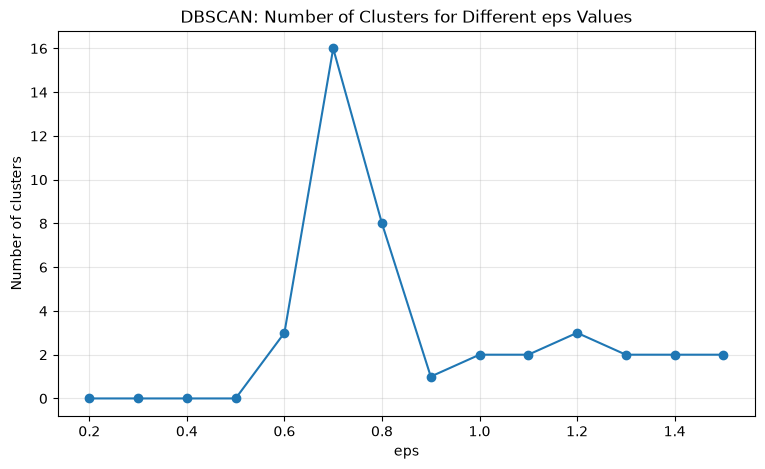

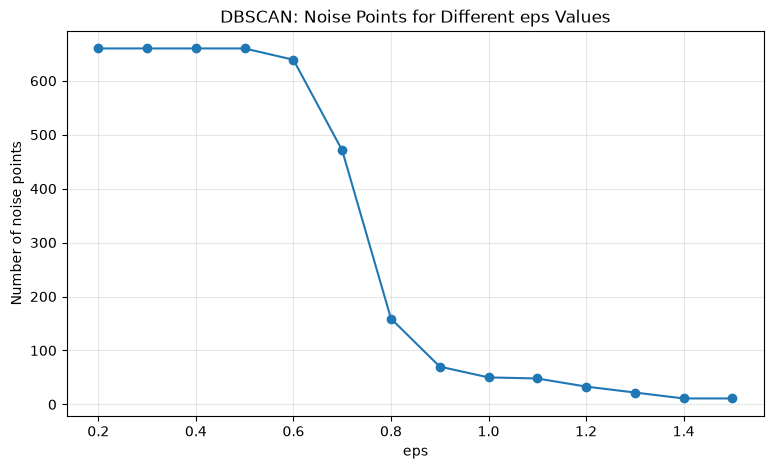

,eps,n_clusters,n_noise
0,0.2,0,660
1,0.3,0,660
2,0.4,0,660
3,0.5,0,660
4,0.6,3,639
5,0.7,16,471
6,0.8,8,159
7,0.9,1,70
8,1.0,2,50
9,1.1,2,48


In [18]:
eps_values = np.arange(0.2, 1.51, 0.1)

cluster_counts = []
noise_counts = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)

    cluster_counts.append(n_clusters)
    noise_counts.append(n_noise)

# Menampilkan jumlah cluster untuk setiap eps
plt.figure(figsize=(9, 5))
plt.plot(eps_values, cluster_counts, marker='o')
plt.xlabel('eps')
plt.ylabel('Number of clusters')
plt.title('DBSCAN: Number of Clusters for Different eps Values')
plt.grid(True, alpha=0.3)
plt.show()

# Menampilkan jumlah noise untuk setiap eps
plt.figure(figsize=(9, 5))
plt.plot(eps_values, noise_counts, marker='o')
plt.xlabel('eps')
plt.ylabel('Number of noise points')
plt.title('DBSCAN: Noise Points for Different eps Values')
plt.grid(True, alpha=0.3)
plt.show()

# Menampilkan tabel perbandingan
comparison = pd.DataFrame({
    'eps': eps_values,
    'n_clusters': cluster_counts,
    'n_noise': noise_counts
})

display(comparison)

Pemilihan parameter DBSCAN dilakukan dengan mengamati k-distance plot dan membandingkan jumlah cluster serta jumlah noise pada beberapa nilai eps. Nilai eps tidak dipilih hanya karena menghasilkan cluster paling banyak atau noise paling sedikit, tetapi berdasarkan keseimbangan antara struktur cluster yang terbentuk dan jumlah data yang dianggap noise.

##### 6. Silhouette score and DBI

In [16]:
# Memisahkan data non-noise
non_noise_mask = dbscan_labels != -1

X_eval = X_scaled[non_noise_mask]
labels_eval = dbscan_labels[non_noise_mask]

# Menghitung jumlah cluster non-noise
unique_clusters = np.unique(labels_eval)
n_clusters_eval = len(unique_clusters)

print("Jumlah cluster non-noise:", n_clusters_eval)
print("Jumlah data non-noise:", len(labels_eval))
print("Jumlah data noise:", np.sum(~non_noise_mask))

if n_clusters_eval >= 2 and len(labels_eval) > n_clusters_eval:
    sil_score = silhouette_score(X_eval, labels_eval)
    dbi_score = davies_bouldin_score(X_eval, labels_eval)

    print(f"Silhouette Score DBSCAN: {sil_score:.4f}")
    print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")
else:
    print(
        "Silhouette Score dan DBI tidak dapat dihitung secara bermakna "
        "karena jumlah cluster non-noise kurang dari 2 "
        "atau jumlah data tidak mencukupi."
    )


Jumlah cluster non-noise: 1
Jumlah data non-noise: 5
Jumlah data noise: 655
Silhouette Score dan DBI tidak dapat dihitung secara bermakna karena jumlah cluster non-noise kurang dari 2 atau jumlah data tidak mencukupi.


Evaluasi model DBSCAN dilakukan menggunakan Silhouette Score dan Davies-Bouldin Index (DBI). Silhouette Score digunakan untuk mengevaluasi kekompakan cluster dan pemisahan antarkelompok, sedangkan DBI digunakan untuk menilai kesamaan antarkelompok berdasarkan penyebaran dan jaraknya.

Nilai kedua metrik dihitung pada data yang tidak ditandai sebagai noise oleh DBSCAN. Silhouette Score yang lebih tinggi dan DBI yang lebih rendah umumnya menunjukkan hasil clustering yang lebih baik. Namun, kedua metrik perlu diinterpretasikan bersama jumlah cluster dan jumlah data noise agar kualitas pengelompokan tidak dinilai hanya dari satu angka.
